### Weather Analysis

This report is to focus on the relationship between temperature vs. taxi demand

### Import

In [53]:
# Data processing
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# machine learning / regression
from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

# preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso


# metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error, accuracy_score
import numpy as np

# date time
from datetime import datetime

### Data Loading

In [21]:
nyc_weather_hourly = pd.read_csv("../data/raw/nyc_weather_hourly.csv")
yellow_taxi = pd.read_csv("../data/raw/yellow_tripdata_2026-01_cleaned.csv")

/var/folders/6f/wmz_js4n0_vckk43lqnkbd5h0000gn/T/ipykernel_90778/1623600644.py:2: DtypeWarning: Columns (6: store_and_fwd_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  yellow_taxi = pd.read_csv("../data/raw/yellow_tripdata_2026-01_cleaned.csv")


### Table Joining

### Basic inspection into column names and data types

In [22]:
nyc_weather_hourly.columns.tolist()

['date',
 'temperature_2m',
 'precipitation',
 'rain',
 'snowfall',
 'wind_speed_10m']

In [23]:
nyc_weather_hourly.dtypes

date                  str
temperature_2m    float64
precipitation     float64
rain              float64
snowfall          float64
wind_speed_10m    float64
dtype: object

In [24]:
nyc_weather_hourly['date_hour'] = pd.to_datetime(nyc_weather_hourly['date'])
nyc_weather_hourly.head(n=10)

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour
0,2026-01-01 00:00:00,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00
1,2026-01-01 01:00:00,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00
2,2026-01-01 02:00:00,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00
3,2026-01-01 03:00:00,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00
4,2026-01-01 04:00:00,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00
5,2026-01-01 05:00:00,33.2,0.000,0.0,0.000,9.5,2026-01-01 05:00:00
6,2026-01-01 06:00:00,32.8,0.000,0.0,0.000,9.2,2026-01-01 06:00:00
7,2026-01-01 07:00:00,32.2,0.008,0.0,0.055,10.2,2026-01-01 07:00:00
8,2026-01-01 08:00:00,27.5,0.028,0.0,0.193,13.1,2026-01-01 08:00:00
9,2026-01-01 09:00:00,24.7,0.000,0.0,0.000,13.2,2026-01-01 09:00:00


In [25]:
yellow_taxi.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee',
 'is_negative_total',
 'is_matched_reversal']

In [26]:
yellow_taxi.dtypes

VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
store_and_fwd_flag           str
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_congestion_fee       float64
is_negative_total           bool
is_matched_reversal         bool
dtype: object

### Creating a new column for the date_hour

In [27]:
yellow_taxi['date_hour'] = pd.to_datetime(yellow_taxi['tpep_pickup_datetime'])
yellow_taxi.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,is_negative_total,is_matched_reversal,date_hour
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,3.66,0.0,1.0,15.86,2.5,0.0,0.00,False,False,2026-01-01 00:54:04
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,0.00,0.0,1.0,13.65,2.5,0.0,0.75,False,False,2026-01-01 00:34:04
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,2.50,0.0,1.0,18.95,2.5,0.0,0.75,False,False,2026-01-01 00:57:06
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,11.11,0.0,1.0,55.56,2.5,0.0,0.75,False,False,2026-01-01 00:15:22
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,3.85,0.0,1.0,23.10,2.5,0.0,0.75,False,False,2026-01-01 00:27:13


### Extracting date and hour

In [28]:
nyc_weather_hourly['date'] = nyc_weather_hourly['date_hour'].dt.date
nyc_weather_hourly['hour'] = nyc_weather_hourly['date_hour'].dt.hour

yellow_taxi['date'] = yellow_taxi['date_hour'].dt.date
yellow_taxi['hour'] = yellow_taxi['date_hour'].dt.hour

### Inspecting creation results

In [29]:
nyc_weather_hourly.head()

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour,hour
0,2026-01-01,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00,0
1,2026-01-01,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00,1
2,2026-01-01,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00,2
3,2026-01-01,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00,3
4,2026-01-01,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00,4


In [30]:
yellow_taxi.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,is_negative_total,is_matched_reversal,date_hour,date,hour
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,1.0,15.86,2.5,0.0,0.00,False,False,2026-01-01 00:54:04,2026-01-01,0
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,1.0,13.65,2.5,0.0,0.75,False,False,2026-01-01 00:34:04,2026-01-01,0
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,1.0,18.95,2.5,0.0,0.75,False,False,2026-01-01 00:57:06,2026-01-01,0
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,1.0,55.56,2.5,0.0,0.75,False,False,2026-01-01 00:15:22,2026-01-01,0
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,1.0,23.10,2.5,0.0,0.75,False,False,2026-01-01 00:27:13,2026-01-01,0


### Aggregate the taxi data together into hours

In [31]:
yellow_taxi_hours = yellow_taxi.groupby(['date', 'hour'], as_index=False).agg(
    trip_count=('tpep_pickup_datetime', 'size'),
    total_revenue=('total_amount', 'sum')
)

yellow_taxi_hours.head()

,date,hour,trip_count,total_revenue
0,2026-01-01,0,9294,295771.15
1,2026-01-01,1,10254,397340.42
2,2026-01-01,2,7853,270398.29
3,2026-01-01,3,6529,210286.78
4,2026-01-01,4,4108,124208.33


### Joining Dataset together to create a merged dataset

In [32]:
df_merged = pd.merge(
    yellow_taxi_hours,
    nyc_weather_hourly,
    on=['date', 'hour'],
    how='inner',
    validate='one_to_one'
)
df_merged["day_of_the_week"] = df_merged["date_hour"].dt.day_name()
df_merged.head(n=10)

,date,hour,trip_count,total_revenue,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour,day_of_the_week
0,2026-01-01,0,9294,295771.15,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00,Thursday
1,2026-01-01,1,10254,397340.42,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00,Thursday
2,2026-01-01,2,7853,270398.29,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00,Thursday
3,2026-01-01,3,6529,210286.78,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00,Thursday
4,2026-01-01,4,4108,124208.33,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00,Thursday
5,2026-01-01,5,2224,68666.92,33.2,0.000,0.0,0.000,9.5,2026-01-01 05:00:00,Thursday
6,2026-01-01,6,2092,76141.47,32.8,0.000,0.0,0.000,9.2,2026-01-01 06:00:00,Thursday
7,2026-01-01,7,1930,66713.16,32.2,0.008,0.0,0.055,10.2,2026-01-01 07:00:00,Thursday
8,2026-01-01,8,1719,52598.27,27.5,0.028,0.0,0.193,13.1,2026-01-01 08:00:00,Thursday
9,2026-01-01,9,2245,65808.13,24.7,0.000,0.0,0.000,13.2,2026-01-01 09:00:00,Thursday


# Models

## Define Data

In [33]:
# Data split on time
df_sorted = df_merged.sort_values(by="date_hour", ascending=True).copy()

split_index = int(len(df_sorted) * 0.8)
df_train = df_sorted.iloc[:split_index]
df_test = df_sorted.iloc[split_index:]

Documentation:

We sorted data based on the date hour columns so that the data can be sorted by the time in an ascending order.

We split the data by indexes. The top 80% of the rows are going to be used for training and the last 20% of the rows are going to be used for testing. We are not going to use random splitting because we are trying to use the past data to predict the future.

We organized useful columns into numeric features and categorical features. The target columns is the trip column since that is what we are trying to predict in the end.

We defined transformers. There isn't anything to do for numeric features since we have already cleaned out all the null values and there are not null values in the weather report. Standard scaling is not useful here because we are not using Lasso or Ridge. OLS does not require scaling and it makes the interpretation in standard units instead of the original units. For the categorical columns we are using dummy encoding method to drop the first column to avoid exact collinearity and ignore unknown values. There are no missing values in the dataset so handle unknown doesn't really do anything other than being a safety check here.

We defined the preprocessor for the numeric and categorical transformers.

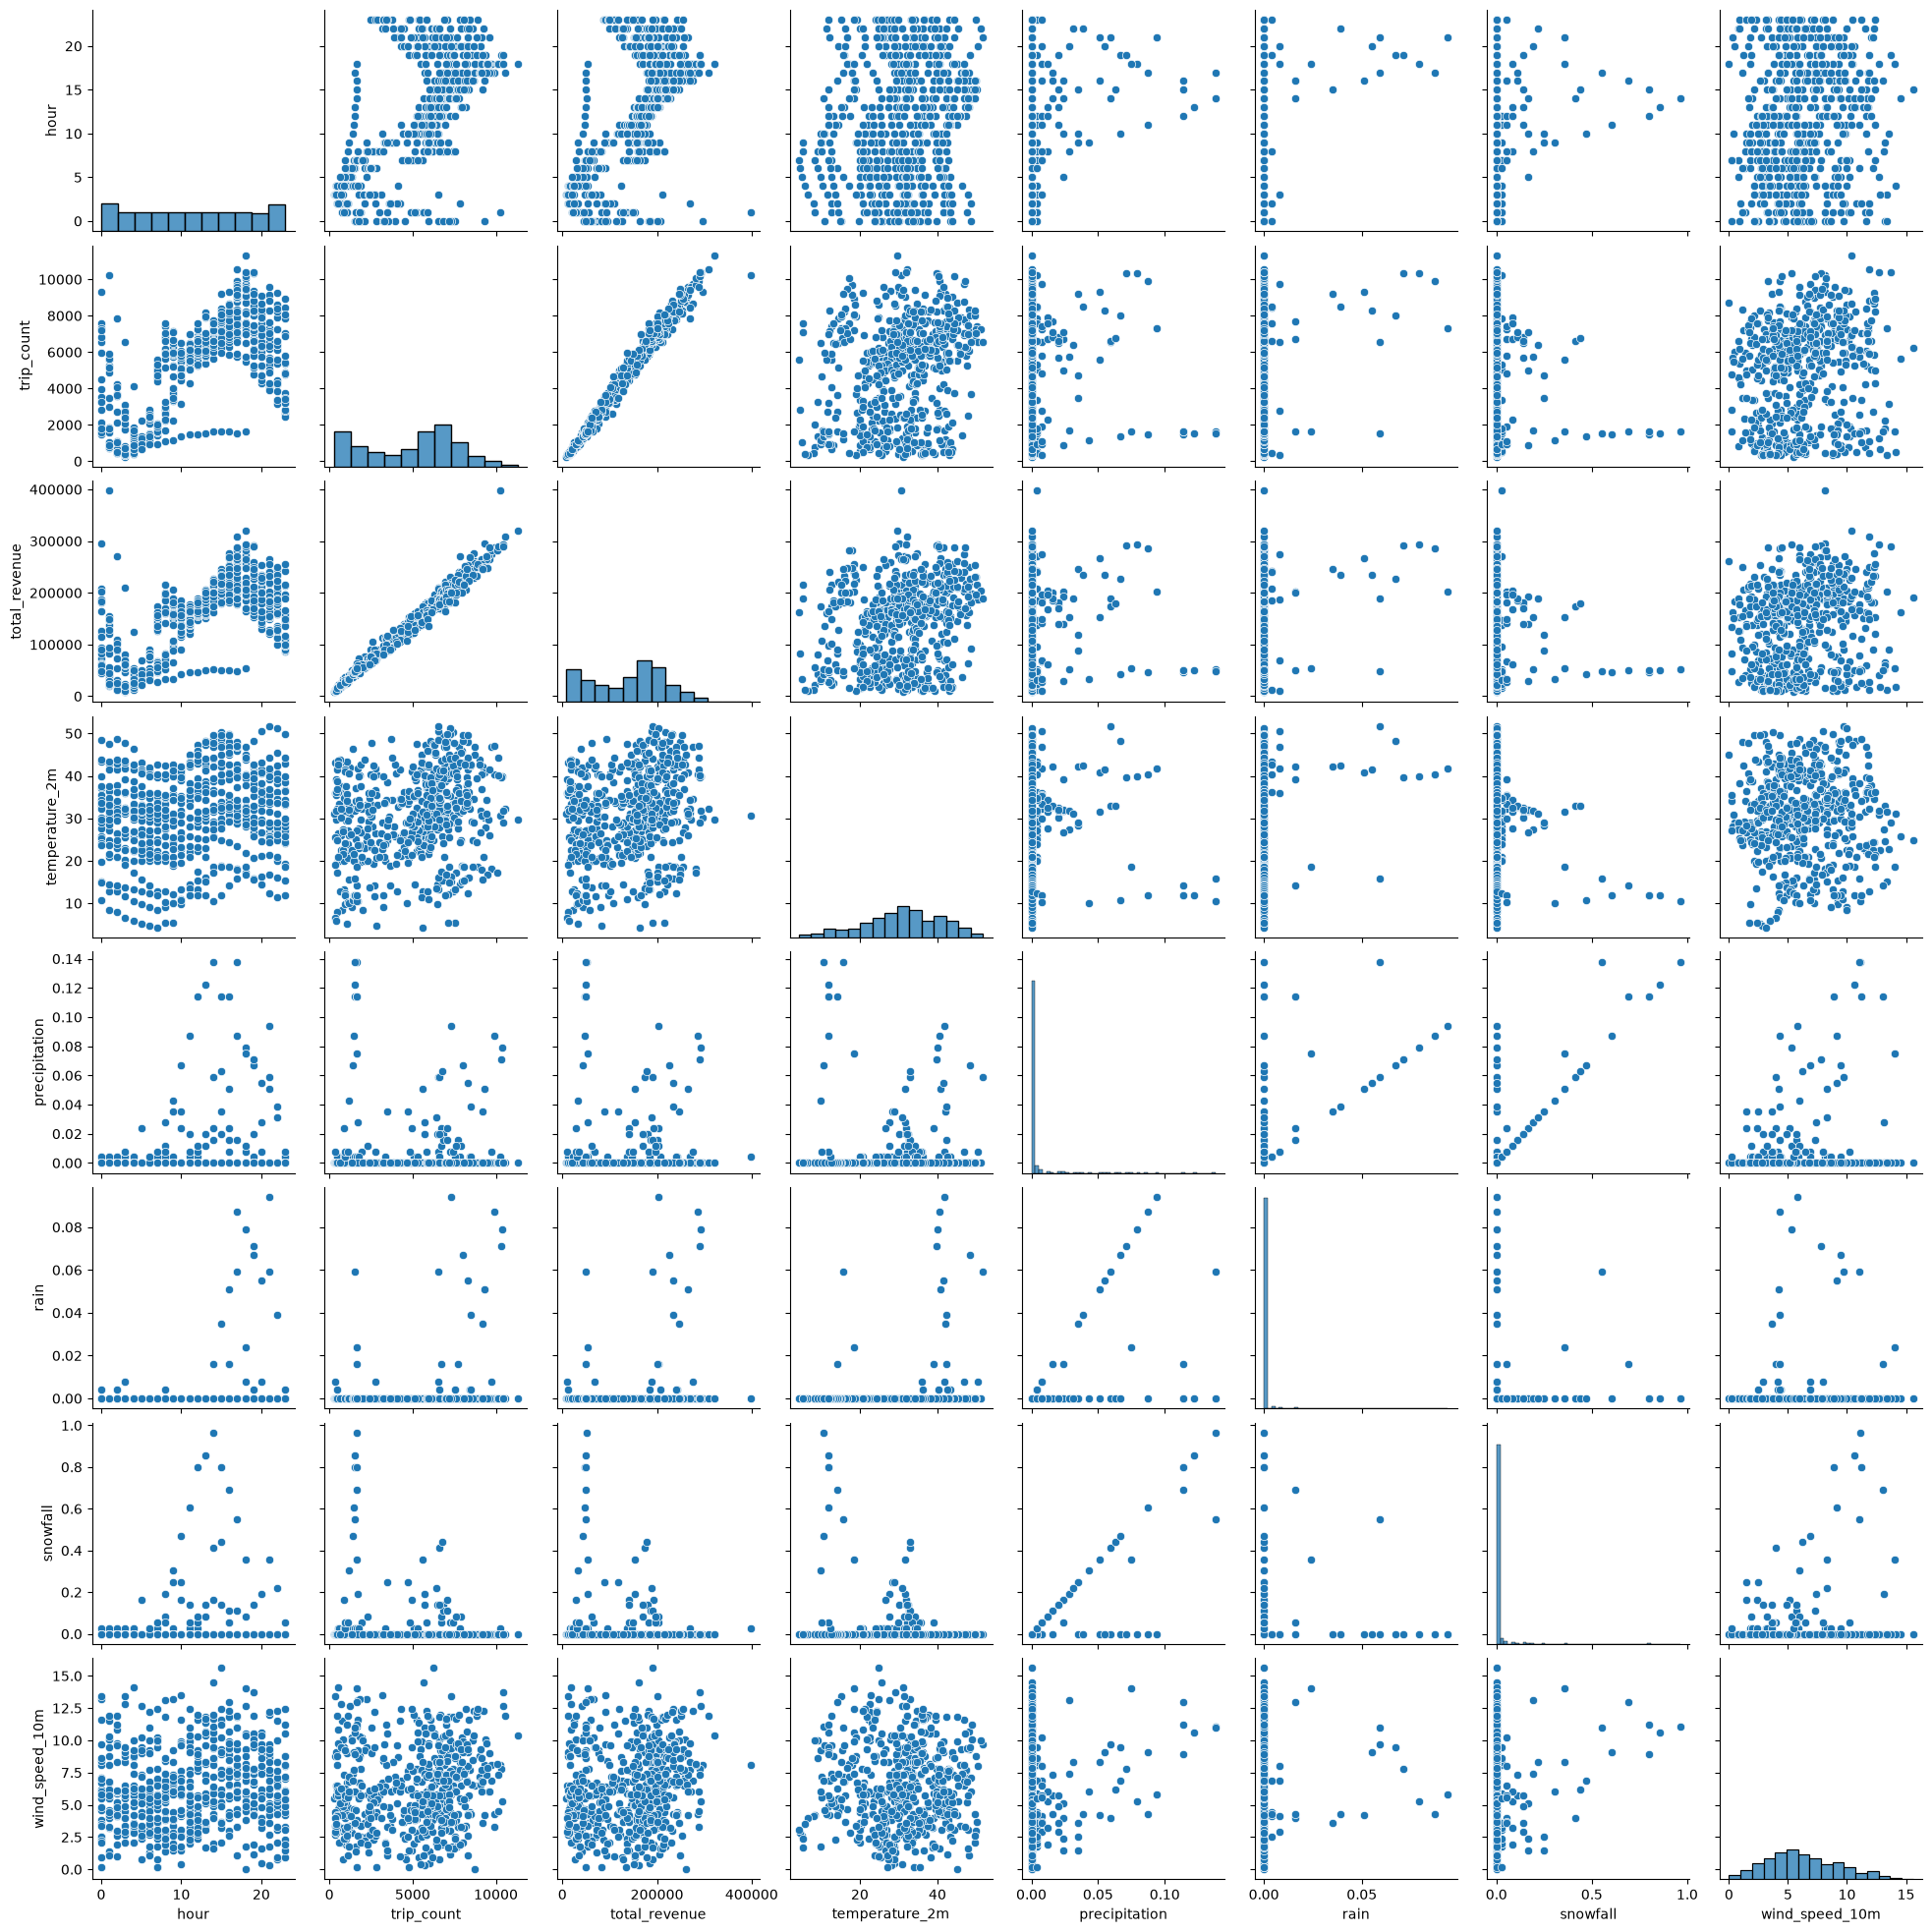

In [34]:
# Visualization of how each feature correlate with each other in the training data
sns.pairplot(df_train)
plt.show()

## Dummy Model

This model guesses the median for every single input. Meaning that it guesses the median trip count for every single input feature

In [35]:
# Preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# Define transformer
numeric_transformer = "passthrough"

categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

dummy_model = DummyRegressor(strategy="median")
dummy_model.fit(X_train, y_train)

y_train_pred = dummy_model.predict(X_train)
y_test_pred = dummy_model.predict(X_test)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Dummy Model Train RMSE: {train_rmse:.3f}")
print(f"Dummy Model Test RMSE: {test_rmse:.3f}")

Dummy Model Train RMSE: 2839.982
Dummy Model Test RMSE: 3227.537


## First Order OLS

Theory: $Y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_p x_p + \epsilon$

Usual methods: Minimize the residual sum of squares (RSS)

Linear Model Assumptions:

* Linearity: The target is a linear combination of the features, plus an error term
* Independence: The errors are independent
* Normality: The errors are normally distributed
* Equal Variance: The errors have constant variance

Implicit Assumptions:

* No perfect multicollinearity
* Fixed x
* More samples than features

The purpose of this model is to use columns information to predict the demand of taxi usage, which is total trip count.

In [36]:
# Preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# Define transformer
numeric_transformer = "passthrough"

categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

# Fitting the first order linear regression model
first_order_ols = Pipeline([
    ("preprocessor", preprocessor),
    ("lr_first", LinearRegression()),
])
_ = first_order_ols.fit(X_train, y_train)

# Reporting coefficients to the model

# Extract the model from the pipeline
transform_step = first_order_ols.named_steps['preprocessor']
linear_model_step = first_order_ols.named_steps['lr_first']

coefficients_names = transform_step.get_feature_names_out()
coefficients = linear_model_step.coef_

# Store the values into a dataframe
coefficients_df = pd.DataFrame({
    "Coefficients Name" : coefficients_names,
    "Coefficients Number" : coefficients
})

coefficients_df

,Coefficients Name,Coefficients Number
0,passthrough__temperature_2m,3.104557
1,passthrough__precipitation,8922.237712
2,passthrough__snowfall,-7706.189233
3,passthrough__wind_speed_10m,19.562314
4,onehotencoder__hour_1,-1050.560975
5,onehotencoder__hour_2,-1842.516555
6,onehotencoder__hour_3,-2380.430634
7,onehotencoder__hour_4,-2740.556812
8,onehotencoder__hour_5,-2634.676517
9,onehotencoder__hour_6,-1708.319360


In [37]:
# Evalute the model performance
train_rmse_first = root_mean_squared_error(
    y_train,
    first_order_ols.predict(X_train)
)

test_rmse_first = root_mean_squared_error(
    y_test,
    first_order_ols.predict(X_test)
)

print(f"First Order Linear Regression Train RMSE: {train_rmse_first:.3f}")
print(f"First Order Linear Regression Test RMSE: {test_rmse_first:.3f}")

First Order Linear Regression Train RMSE: 1382.370
First Order Linear Regression Test RMSE: 1733.734


## Second Order OLS

Second order OLS captures simple non-linear pattern that first-order OLS cannot

In [ ]:
# Preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# Define transformer

# numeric_transformer
numeric_transformer = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# categorical transformer
categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

# preprocessing data
preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

# pipeline to the model
second_order_ols = Pipeline([
    ("preprocessor", preprocessor),
    ("lr", LinearRegression())
])

_ = second_order_ols.fit(X_train, y_train)

preprocessor_step = second_order_ols.named_steps["preprocessor"]
model_step = second_order_ols.named_steps["lr"]

coefficients_names = preprocessor_step.get_feature_names_out()
coefficients = model_step.coef_

coefficients_df = pd.DataFrame({
    "Coefficient Name:" : coefficients_names,
    "Coffiicients" : coefficients
})

coefficients_df

,Coefficient Name:,Coffiicients
0,polynomialfeatures__temperature_2m,-63.396442
1,polynomialfeatures__precipitation,16617.119546
2,polynomialfeatures__snowfall,-18979.838341
3,polynomialfeatures__wind_speed_10m,45.846068
4,polynomialfeatures__temperature_2m^2,0.995760
5,polynomialfeatures__temperature_2m precipitation,843.153823
6,polynomialfeatures__temperature_2m snowfall,322.764532
7,polynomialfeatures__temperature_2m wind_speed_10m,0.633282
8,polynomialfeatures__precipitation^2,5053.686691
9,polynomialfeatures__precipitation snowfall,12380.402762


In [39]:
# Evaluate the model
y_train_pred = second_order_ols.predict(X_train)
y_test_pred = second_order_ols.predict(X_test)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Train root mean squared error: {train_rmse:.3f}")
print(f"Test root mean squared error: {test_rmse:.3f}")

Train root mean squared error: 1340.969
Test root mean squared error: 1553.145


## Ridge

$\sum_{i=1}^{n}(y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij})^2 + \lambda \sum_{j=1}^{p} \beta_j^2$

In [54]:
# Preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# Define transformer

# numeric_transformer
numeric_transformer = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    StandardScaler()
)

# categorical transformer
categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

# preprocessing data
preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("ridge", Ridge(alpha=1.0))
])

_ = ridge_model.fit(X_train, y_train)

In [55]:
# Evaluate the model
y_train_pred = ridge_model.predict(X_train)
y_test_pred = ridge_model.predict(X_test)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
tests_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Train root mean squared error:  {train_rmse:.3f}")
print(f"Test root mean squared error: {test_rmse:.3f}")

Train root mean squared error:  1349.987
Test root mean squared error: 1553.145


In [56]:
# Apply Grid Search CV for the best parameter now
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("ridge", Ridge())
])

ridge_params = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

tscv = TimeSeriesSplit(n_splits=5)

ridge_grid = GridSearchCV(
    ridge_model,
    param_grid=ridge_params,
    scoring="neg_root_mean_squared_error"
)

ridge_grid.fit(X_train, y_train)

print("Best alpha: ", ridge_grid.best_params_)
print("Best CV RMSE: ", -ridge_grid.best_score_)

Best alpha:  {'ridge__alpha': 10}
Best CV RMSE:  1835.0344223175357


Note: Best Score function returns the best average cross-validation score achieved during the grid search.

In [62]:
# Using the tuned model to evaluate again
best_ridge = ridge_grid.best_estimator_

y_test_pred = best_ridge.predict(X_test)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Tuned Ridge RMSE: {test_rmse:.3f}")

Tuned Ridge RMSE: 2020.396


Tuned Ridge did not perform better than the regular model where alpha = 1

## LASSO

$\sum_{i=1}^{n} (y_i- \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij})^2 + \lambda \sum_{j=1}^{p} |\beta_j|$

Lasso objective = prediction error + penalty for large coefficients

In [57]:
# Preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# Define transformer

# numeric_transformer
numeric_transformer = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    StandardScaler()
)

# categorical transformer
categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

# preprocessing data
preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("lasso", Lasso(alpha=1.0, max_iter=10000))
])

_ = lasso_model.fit(X_train, y_train)

In [58]:
# Evaluate the model
y_train_pred = lasso_model.predict(X_train)
y_test_pred = lasso_model.predict(X_test)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
tests_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Train root mean squared error:  {train_rmse:.3f}")
print(f"Test root mean squared error: {test_rmse:.3f}")

Train root mean squared error:  1339.950
Test root mean squared error: 1553.145


In [61]:
# Now Apply GridSearch CV to find the best parameter
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("lasso", Lasso(max_iter=10000000))
])

lasso_params = {
    "lasso__alpha" : [0.01, 0.1, 1, 10, 100, 1000]
}

tscv = TimeSeriesSplit(n_splits=5)

lasso_grid = GridSearchCV(
    lasso_model,
    param_grid=lasso_params,
    scoring="neg_root_mean_squared_error",
    cv=tscv
)

lasso_grid.fit(X_train, y_train)

print("Best alpha: ", lasso_grid.best_params_)
print("Best CV RMSE: ", -lasso_grid.best_score_)

/Users/enqiwu/Documents/Research/NYC_TLC_Trip_Record_Analysis/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.384808e+06, tolerance: 5.021e+04
  model = cd_fast.enet_coordinate_descent(
/Users/enqiwu/Documents/Research/NYC_TLC_Trip_Record_Analysis/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/enqiwu/Documents/Research/NYC_TLC_Trip_Record_Analysis/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider incr

Best alpha:  {'lasso__alpha': 1000}
Best CV RMSE:  2832.9947396843518


/Users/enqiwu/Documents/Research/NYC_TLC_Trip_Record_Analysis/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/enqiwu/Documents/Research/NYC_TLC_Trip_Record_Analysis/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [67]:
best_lasso = lasso_grid.best_estimator_

best_lasso.named_steps["lasso"].n_iter_

0

Note: n_iter_ returns the steps of iteration that it took for the model to stop optimizing. At this place the number is zero which means that the model immediately stopped optimizing.

In [65]:
y_test_pred = best_lasso.predict(X_test)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Tuned Lasso RMSE: {test_rmse:.3f}")

Tuned Lasso RMSE: 3203.043


Lasso heavily shrank the model and performed poorly. This is no longer worth the time to continue on investigation.

## Non-linear regression models

### Random Forrest

$\hat{y}_{\text{forest}} = \frac{1}{B} \sum_{b=1}^{B} \hat{y_b}$

In [87]:
# preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# categorical transformer
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# preprocessing data
preprocessor = make_column_transformer(
    ("passthrough", numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

pipeline = Pipeline(
    [("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))]
)

rf_params = {
    "regressor__n_estimators": [100, 300, 500],

    "regressor__max_depth": [None, 5, 10, 20],

    "regressor__min_samples_split": [2, 5, 10],

    "regressor__min_samples_leaf": [1, 2, 5, 10],

    "regressor__max_features": [
        "sqrt",
        0.5,
        1.0
    ]
}

tscv = TimeSeriesSplit(n_splits=5)

tuned_model = GridSearchCV(
    pipeline,
    param_grid=rf_params,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    verbose=1,
    n_jobs=-1
)

_ = tuned_model.fit(X_train, y_train)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits


n_estimators are the number of trees created to calculate on the average result.

max_depths are used to determine how deep can the tree go. The deeper that a tree grow the more overfitting potential there is.

min_sample_split determine how many observations do I must have in each leaf before that I am allowed to split. Larger values stop the tree from making decisions based on tiny group of observations. Bigger value = more conservative tree.

min_sample_leaf determins how many observations do I must have in the final leaf. This is slightly different from min_sample_split. Larger leaves make predictions smoother and more stable.

max_features determine how many candidate feature the tree is allowed to consider at each split. The more features the more likely the tree is going to be similiar. Smaller numbers allow trees to be more different, though too small may cause trees to miss important factors.

In [88]:
# Evaluate model performance
tuned_model.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['temperature_2m','precipitation','snowfall','wind_speed_10m','hour', 'day_of_the_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('passthrough', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

In [89]:
tuned_model.best_params_

{'regressor__max_depth': None,
 'regressor__max_features': 'sqrt',
 'regressor__min_samples_leaf': 1,
 'regressor__min_samples_split': 2,
 'regressor__n_estimators': 500}

In [90]:
print(f"Best Model, CV RMSE: {-tuned_model.best_score_:.3f}")

Best Model, CV RMSE: 2127.696


In [91]:
print(f"Test RMSE: {-tuned_model.score(X_test, y_test):.3f}")

Test RMSE: 1846.081


Random Forest achieved a performance of RMSE 1846.081. This is still worse than the second order OLS model.

# Histogram Gradient Boosting Regression Trees

In [92]:
# preprocessing

# Define numeric and categorical features
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

# Define training data and testing data
X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

# categorical transformer
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# preprocessing data
preprocessor = make_column_transformer(
    ("passthrough", numeric_features),
    (categorical_transformer, categorical_features),
    remainder="drop"
)

pipeline = Pipeline(
    [("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(random_state=42))]
)

hgb_params = {
    "regressor__learning_rate": [0.05, 0.1],
    "regressor__max_iter": [100, 300],
    "regressor__max_leaf_nodes": [15, 31],
    "regressor__min_samples_leaf": [10, 20, 30],
    "regressor__l2_regularization": [0.0, 1.0, 10.0]
}

tscv = TimeSeriesSplit(n_splits=5)

tuned_model = GridSearchCV(
    pipeline,
    param_grid=hgb_params,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    verbose=1,
    n_jobs=-1
)

_ = tuned_model.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


regressor_learning_rate represents how much each tree is allowed to correct the existing model. smaller = slower/more conservative learning; larger = faster/more aggressive

max_iter - effectively the number of boosting rounds/trees built. Here it is controlling the model size.

max_leaf_nodes - controls how complicated each individual tree can become. More leaf nodes mean that each tree is more complicated.

min_samples_leaf - forces every leaf to contain at least this many observations. Larger values make the model smoother and reduce overfitting.

l2_regularization - penalizes overly aggressive leaf predictions. Larger values = more regularization.

In [93]:
tuned_model.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['temperature_2m','precipitation','snowfall','wind_speed_10m','hour', 'day_of_the_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('passthrough', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

In [94]:
tuned_model.best_params_

{'regressor__l2_regularization': 1.0,
 'regressor__learning_rate': 0.1,
 'regressor__max_iter': 300,
 'regressor__max_leaf_nodes': 15,
 'regressor__min_samples_leaf': 10}

In [98]:
print(f"Best Model, CV RMSE: {-tuned_model.best_score_:.3f}")

Best Model, CV RMSE: 2399.034


In [96]:
print(f"Test RMSE: {-tuned_model.score(X_test, y_test):.3f}")

Test RMSE: 1965.747


This model performance is slightly worse than random forest, achieveing a RMSE of 1965.747.